# 01 · Dataset audit — Salat Postures (provided sample)

This notebook locates the dataset (folder **or** ZIP), extracts it safely, and audits what is actually inside:
structure, labels, quality, near-duplicates and leakage risks. Every number below is computed from the files.

Paths come from `configs/default.yaml` (override with `SALAT_DATASET_ZIP` / `SALAT_DATASET_DIR`).

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("GLOG_minloglevel", "2")
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from salat_vision.config import get_config
from salat_vision.viz import apply_style
apply_style()
cfg = get_config()
print("project root:", ROOT)

project root: /home/user/Shalat-Postures-Detection


## 1. Discover and (safely) extract the dataset

In [2]:
from salat_vision.data.extract import discover_dataset, inspect_zip, safe_extract, DATASET_NAME
dataset_dir = cfg.path("dataset_dir")
zip_path = os.environ.get("SALAT_DATASET_ZIP") or cfg.get("paths", "dataset_zip")
print("configured dataset folder:", dataset_dir.relative_to(ROOT), "| exists:", dataset_dir.is_dir())
if zip_path:
    rep = inspect_zip(zip_path)
    print(f"archive: {rep.n_files} files, {rep.uncompressed_bytes/1e6:.2f} MB, safe={rep.is_safe}, prefix='{rep.common_prefix}'")
    safe_extract(zip_path, cfg.path("raw_dir"))
elif not dataset_dir.is_dir():
    print("discovery:", discover_dataset())
extraction = json.loads((ROOT / "artifacts/reports/extraction_report.json").read_text())
print("recorded extraction:", {k: extraction[k] for k in ("n_entries", "n_files", "uncompressed_bytes", "is_safe", "extracted_to")})

configured dataset folder: data/raw/Salat-Postures-Dataset-main | exists: True
recorded extraction: {'n_entries': 84, 'n_files': 82, 'uncompressed_bytes': 11847447, 'is_safe': True, 'extracted_to': 'data/raw/Salat-Postures-Dataset-main'}


In [3]:
for p in sorted(dataset_dir.iterdir()):
    n = sum(1 for _ in p.rglob('*')) if p.is_dir() else None
    print(f"{p.name:40s}", f"{n} files" if n is not None else f"{p.stat().st_size} bytes")
print((dataset_dir / "README.md").read_text()[:900])

README.md                                2779 bytes
Sample-images-with-annotations           81 files
# Salat-Postures-Dataset
Annotated dataset of salat (islamic prayer) postures for object detection 

We have built the Salat Postures Dataset from a set of images of students and laboratory members performing different Salat positions using mobile phones, from various view angles and with different brightness conditions, especially captured for the purpose, complemented with images (and video frames) of people in prayer collected from the Internet. 

The total number of collected images is 1904 (file extensions: jpeg, jpg, png, PNG, mpo), which we manually labeled into four classes using rectangular bounding boxes. Each image is associated with an XML file with the same name, containing the class annotations and bounding box coordinates, following the Pascal VOC format. The four classes correspond to the four main positions in Islamic prayer:

- 'qiyam' (standing position): 624 instanc

## 2. Image and annotation index

In [4]:
from salat_vision.data.dataset import build_index
idx = build_index(cfg=cfg)
im, inst = idx.images, idx.instances
print(f"image files: {len(im)} | with annotation: {im.has_annotation.sum()} | without: {(~im.has_annotation).sum()} | orphan XML: {len(idx.orphan_annotations)}")
print(f"annotated person instances: {len(idx.labeled_instances)} in {idx.labeled_instances.image_id.nunique()} images")
im[["image_id", "ext", "width", "height", "has_annotation", "n_objects", "labels", "source_kind"]].head(12)

image files: 41 | with annotation: 37 | without: 4 | orphan XML: 2
annotated person instances: 40 in 37 images


,image_id,ext,width,height,has_annotation,n_objects,labels,source_kind
0,23,.jpg,1920,1080,True,1,julus,numbered photo
1,6,.jpg,1920,1080,True,1,julus,numbered photo
2,7,.jpg,1920,1080,True,1,julus,numbered photo
3,IMG-20191019-WA0062,.jpg,960,1280,True,1,julus,messaging app photo
4,IMG_1454,.jpg,3024,4032,True,1,julus,phone camera photo
5,SittingMO56,.jpg,1920,1080,True,1,julus,named series (sittingmo)
6,SittingMo58,.jpg,640,480,True,1,julus,named series (sittingmo)
7,SittingMo85,.jpg,640,480,True,1,julus,named series (sittingmo)
8,ck2opyry31w790721ewbyuxzl,.jpeg,320,240,True,3,qiyam,web (Labelbox export)
9,ck2oqgwn04qu60757lizr6lif,.jpeg,1080,1920,False,0,,web (Labelbox export)


In [5]:
print("raw label spellings:", inst.raw_label.value_counts().to_dict())
print("box formats:", inst.box_format.value_counts().to_dict())
idx.orphan_annotations

raw label spellings: {'qiyam': 12, 'sujud': 12, 'sitting': 8, 'ruku': 6, 'julus': 2}
box formats: {'bndbox': 39, 'polygon': 1}


,xml_file,filename_field,xml_size,labels,n_objects
0,Sample-images-with-annotations/ck2oqg3o222pb07...,ck2oqg3o222pb0721niv1tjox.jpeg,170x250,julus,1
1,Sample-images-with-annotations/qiam(23).xml,qiam (23).jpg,480x360,qiyam,1


## 3. Class distribution — only four postures are annotated

,instances,images,independent groups
qiyam,12,10,10
ruku,6,6,6
sujud,12,11,11
julus,10,10,4


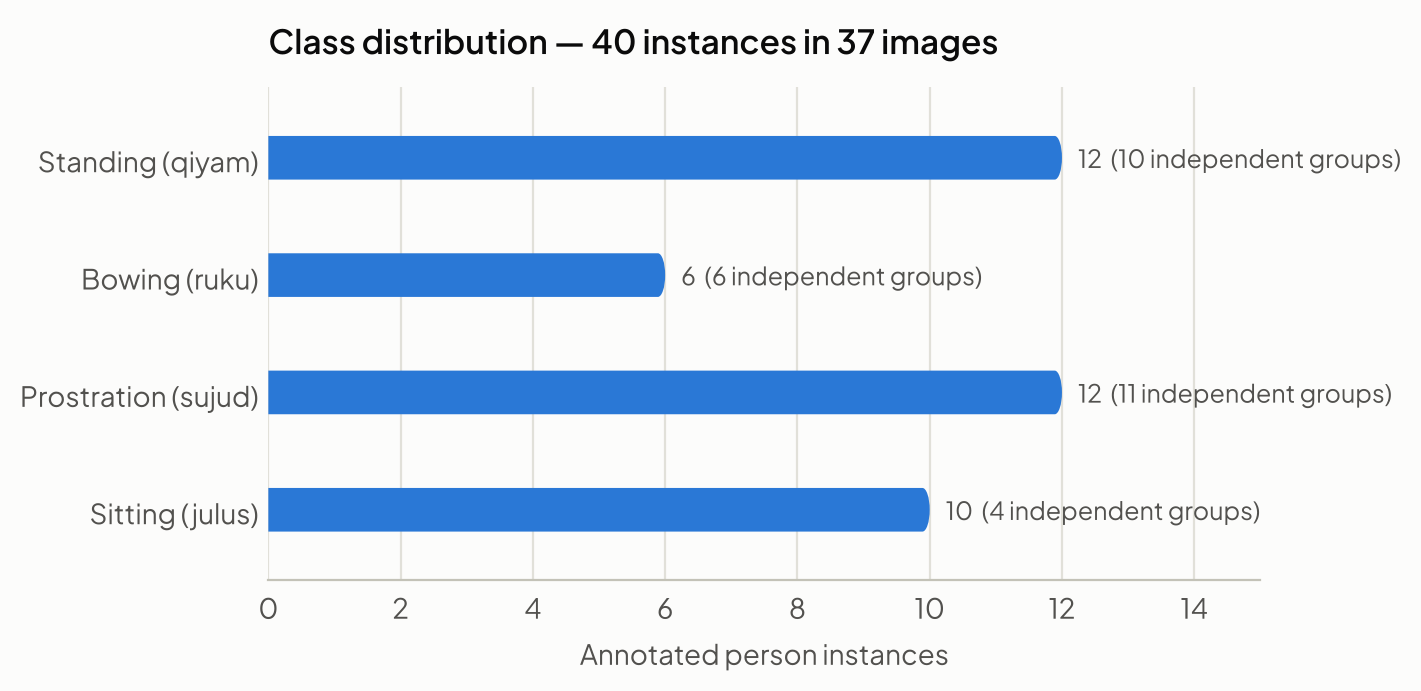

,support in this dataset
Standing (qiyam),annotated (qiyam)
Bowing (rukuk),annotated (ruku)
Prostration (sujud),annotated (sujud / Sujud)
Standing after bowing (iktidal),NOT annotated — visually identical to standing...
Sitting between prostrations,NOT annotated separately — annotated as generi...
Testimony sitting (tasyahud),NOT annotated separately — annotated as generi...


In [6]:
from salat_vision.data import audit
idx2, summary = audit.run_audit(cfg)
li = idx2.labeled_instances
display(pd.DataFrame({"instances": summary["instances_per_class"], "images": summary["images_per_class"],
                      "independent groups": summary["independent_groups_per_class"]}))
display(Image(str(ROOT / "artifacts/figures/dataset_class_distribution.png"), width=720))
pd.Series(summary["phase_support"], name="support in this dataset").to_frame()

## 4. Quality checks

In [7]:
print("unreadable images:", summary["n_unreadable_images"], "| EXIF-rotated:", summary["exif_rotated_images"],
      "| XML size mismatches:", summary["xml_size_mismatches"], "| exact duplicates:", summary["exact_duplicate_files"])
print("width px:", summary["width_px"], "\nheight px:", summary["height_px"])
print("box area / image area:", {k: round(v, 3) for k, v in summary["box_rel_area"].items()})
pd.DataFrame(summary["issues"])

unreadable images: 0 | EXIF-rotated: 0 | XML size mismatches: 0 | exact duplicates: 0
width px: {'min': 183, 'median': 768.0, 'max': 4032} 
height px: {'min': 159, 'median': 900.0, 'max': 4032}
box area / image area: {'min': 0.038, 'median': 0.319, 'max': 0.807}


,file,issue,detail
0,Sample-images-with-annotations/ck2oqgwn04qu607...,image without annotation,excluded from supervised training
1,Sample-images-with-annotations/qiam(24).jpg,image without annotation,excluded from supervised training
2,Sample-images-with-annotations/sujud31.jpg,image without annotation,excluded from supervised training
3,Sample-images-with-annotations/sujud32.jpg,image without annotation,excluded from supervised training
4,ck2oqg3o222pb0721niv1tjox.xml,annotation without image,<filename>=ck2oqg3o222pb0721niv1tjox.jpeg; not...
5,qiam(23).xml,annotation without image,<filename>=qiam (23).jpg; not paired (no evide...


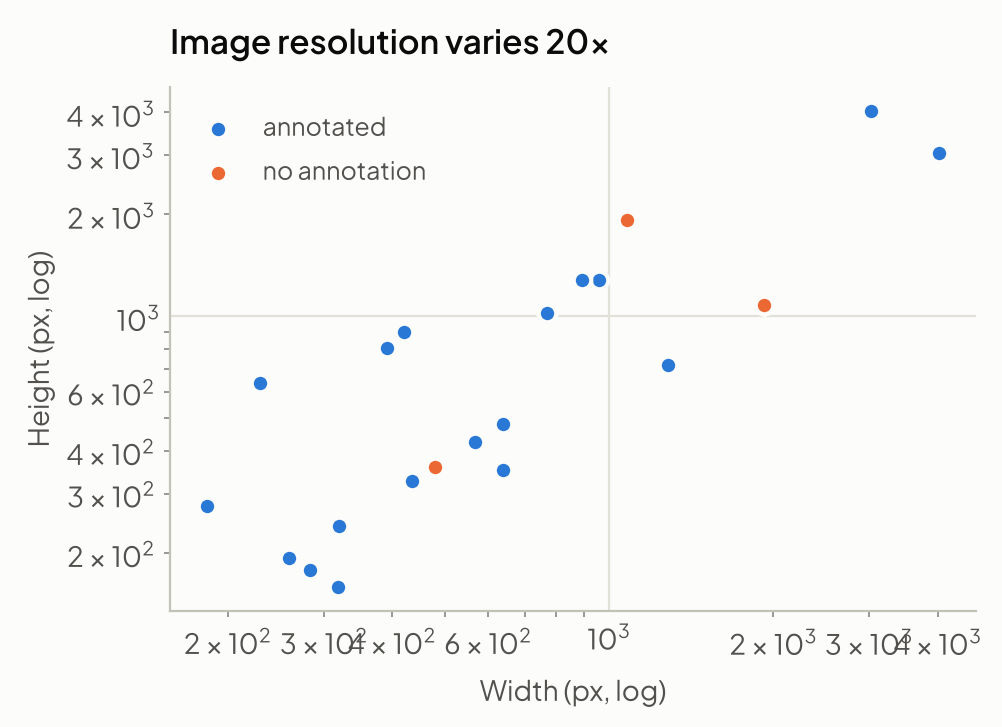

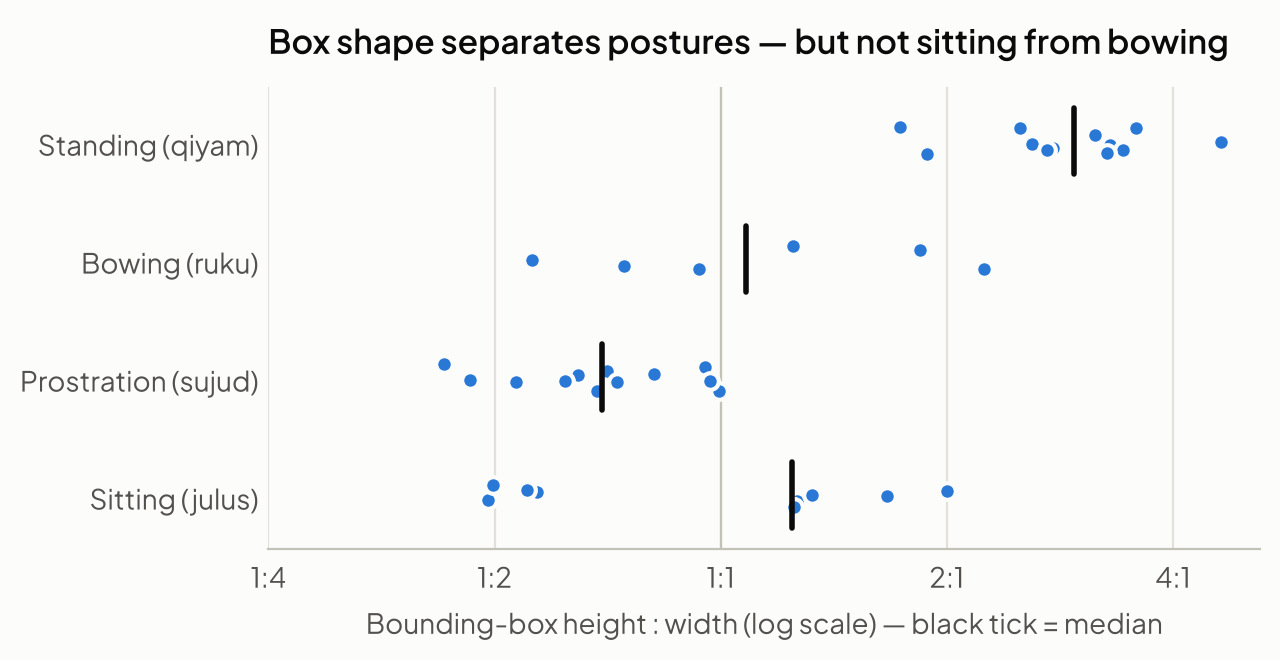

In [8]:
display(Image(str(ROOT / "artifacts/figures/dataset_resolution.png"), width=560))
display(Image(str(ROOT / "artifacts/figures/dataset_box_geometry.png"), width=720))

## 5. Leakage: near-duplicates and capture sessions

In [9]:
links = pd.DataFrame(summary["leakage"]["group_links"])
print(f"labelled groups: {summary['leakage']['n_groups_labeled']} | multi-instance groups: {summary['leakage']['n_multi_instance_groups']} | largest group: {summary['leakage']['largest_group_instances']} instances")
links

labelled groups: 29 | multi-instance groups: 5 | largest group: 6 instances


,image_a,image_b,reason
0,6,7,pHash distance 12 <= 18
1,SittingMo58,ck2or3u694ynn0757ptzgbv8t,pHash distance 16 <= 18
2,SittingMo85,ck2or3u694ynn0757ptzgbv8t,pHash distance 18 <= 18
3,ck2qcfa2rkho8083878ojzlm5,qiam(24),pHash distance 0 <= 18
4,23,6,manual session group 'lab_room_blue_mat'
5,6,7,manual session group 'lab_room_blue_mat'
6,7,SittingMO56,manual session group 'lab_room_blue_mat'
7,SittingMO56,IMG_1454,manual session group 'lab_room_blue_mat'
8,IMG_1454,ruku61,manual session group 'lab_room_blue_mat'
9,ruku61,sujud31,manual session group 'lab_room_blue_mat'


In [10]:
splits = json.loads((ROOT / "data/splits/cv_splits.json").read_text())
groups = pd.read_csv(ROOT / "data/splits/instance_groups.csv").set_index("instance_id")
rows = []
for f in splits["folds"][:5]:
    tr, te = set(groups.loc[f["train"], "group_id"]), set(groups.loc[f["test"], "group_id"])
    rows.append({"fold": f["fold"], "train": len(f["train"]), "test": len(f["test"]), "shared groups": len(tr & te),
                 **groups.loc[f["test"], "label"].value_counts().to_dict()})
pd.DataFrame(rows).fillna(0)

,fold,train,test,shared groups,julus,sujud,qiyam,ruku
0,0,32,8,0,3.0,2,2,1
1,1,33,7,0,0.0,3,2,2
2,2,32,8,0,1.0,3,3,1
3,3,30,10,0,5.0,2,2,1
4,4,33,7,0,1.0,2,3,1


## 6. Shortcut risk: capture source vs. class

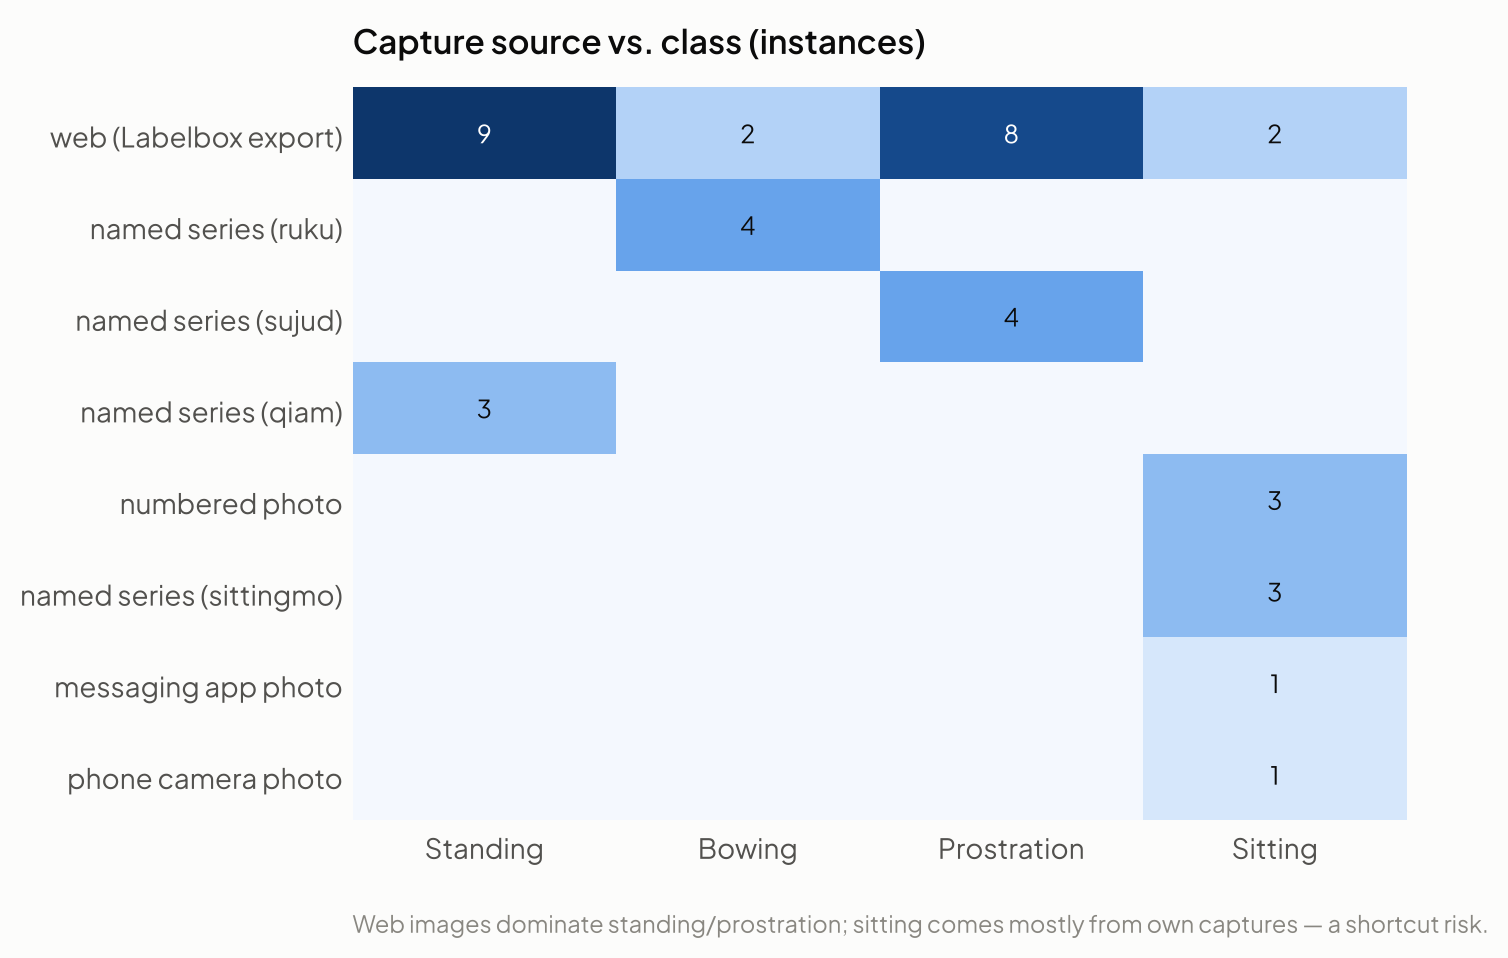

In [11]:
display(Image(str(ROOT / "artifacts/figures/dataset_source_by_class.png"), width=720))

## 7. Examples (faces blurred) with the detected pose skeleton

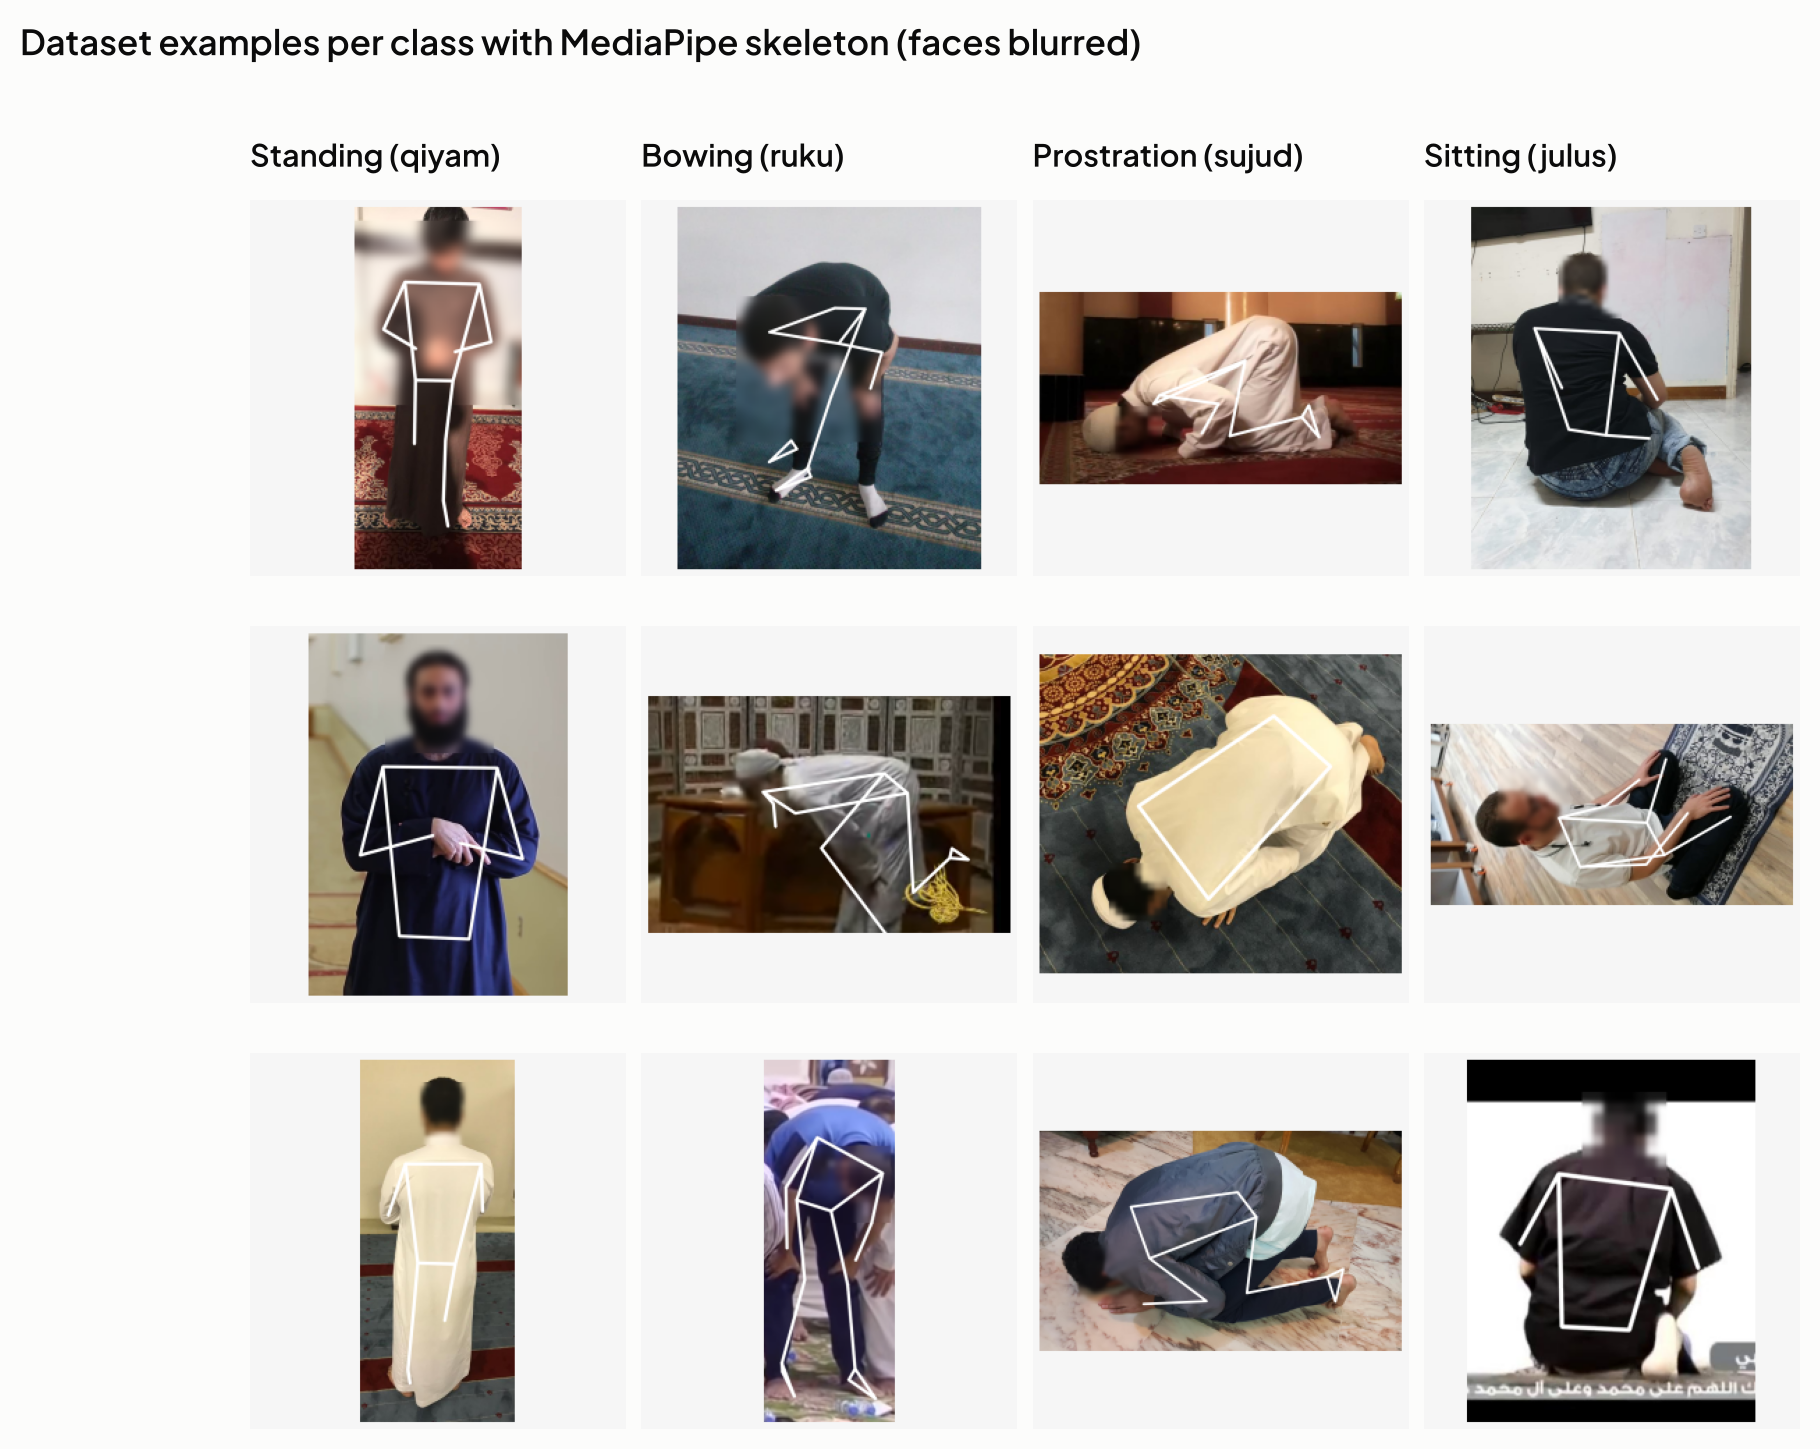

In [12]:
p = ROOT / "artifacts/figures/dataset_samples_anonymized.png"
display(Image(str(p), width=760)) if p.exists() else print("run scripts/make_figures.py to render the anonymised grid")

## 8. Findings and modelling recommendations

* The archive is the **public sample** of the Salat Postures Dataset: 41 images, 40 annotated people, 4 classes.
  The full release (1,904 images) is referenced in the README but is not part of the provided files.
* Two annotation files have no image, four images have no annotation, one annotation is stored as a polygon.
* Images are heterogeneous (web images, phone photos, video frames) and **capture source is confounded with class**.
* Near-duplicates and same-session frames exist across *different file-name families*, so random splits would leak.
  All evaluation therefore uses **stratified group k-fold** on 29 independent groups.
* Iktidal, the sitting between prostrations and tasyahud are **not annotated**; they can only be inferred from temporal
  order in a video. The models learn 4 visual postures; the 6 phases come from a temporal decoder.
* With ~29 effective samples, prefer strong priors (pretrained pose estimation, frozen ImageNet features) and report
  confidence intervals rather than point estimates.